# Практическая работа: Полиномиальная регрессия (Градиентный спуск + МНК)

**Цель работы:** Реализовать класс полиномиальной регрессии, добавив метод градиентного спуска. Важно реализовать нормализацию признаков (Z-score scaling), так как возведение в степень создает огромный разброс масштабов, из-за которого базовый градиентный спуск может 'взорваться'.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (12, 7)

## 1. Реализация класса `MyPolynomialRegression`
Класс поддерживает `method='gd'` и `method='analytical'`. Внутри метода `fit` для градиентного спуска добавлена стандартизация признаков: $\frac{x - \mu}{\sigma}$.

In [2]:
class MyPolynomialRegression:
    def __init__(self, degree=2, method='analytical', learning_rate=0.01, n_iters=1000):
        self.degree = degree
        self.method = method
        self.learning_rate = learning_rate
        self.n_iters = n_iters
        self.weights = None
        self.loss_history = []
        
        self.means = None
        self.stds = None
        
    def _transform_features(self, X):
        if X.ndim == 1:
            X = X.reshape(-1, 1)
            
        n_samples = X.shape[0]
        X_poly = np.ones((n_samples, 1))
        
        for d in range(1, self.degree + 1):
            X_poly = np.hstack((X_poly, X ** d))
            
        return X_poly

    def fit(self, X, y):
        X_poly = self._transform_features(X)
        n_samples, n_features = X_poly.shape
        
        if self.method == 'analytical':
            self.weights = np.linalg.pinv(X_poly.T @ X_poly) @ X_poly.T @ y
            
        elif self.method == 'gd':
            # 1. Нормализация (стандартизация) признаков, кроме столбца единиц
            self.means = np.mean(X_poly[:, 1:], axis=0)
            self.stds = np.std(X_poly[:, 1:], axis=0)
            self.stds[self.stds == 0] = 1
            
            X_poly_scaled = np.copy(X_poly)
            X_poly_scaled[:, 1:] = (X_poly[:, 1:] - self.means) / self.stds
            
            # 2. Инициализация весов и цикл спуска
            self.weights = np.zeros(n_features)
            
            for i in range(self.n_iters):
                predictions = X_poly_scaled @ self.weights
                errors = predictions - y
                
                gradient = (2 / n_samples) * (X_poly_scaled.T @ errors)
                self.weights -= self.learning_rate * gradient
                
                mse = np.mean(errors ** 2)
                self.loss_history.append(mse)
        else:
            raise ValueError("Выберите method='analytical' или 'gd'")

    def predict(self, X):
        X_poly = self._transform_features(X)
        
        if self.method == 'gd':
            X_poly[:, 1:] = (X_poly[:, 1:] - self.means) / self.stds
            
        return X_poly @ self.weights
    
    @staticmethod
    def mse(y_true, y_pred):
        return np.mean((y_true - y_pred) ** 2)
    
    @staticmethod
    def r2_score(y_true, y_pred):
        ss_res = np.sum((y_true - y_pred) ** 2)
        ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
        return 1 - (ss_res / ss_tot)

## 2. Генерация данных
Функция: $y = 0.5x^3 - x^2 - 2x + 5 + \varepsilon$

In [3]:
N_samples = 150
X = np.random.uniform(-3, 4, N_samples)
y_true = 0.5 * X**3 - X**2 - 2*X + 5
noise = np.random.normal(0, 3, size=N_samples)
y = y_true + noise

# Для отрисовки гладких линий
X_plot = np.linspace(-3.5, 4.5, 200)

## 3. Обучение градиентным спуском и аналитическим методом (МНК)
Сравним результаты для полинома 3-й степени.

Градиентный спуск
MSE: 9.4543
R^2: 0.6614

Аналитическое решение (МНК)
MSE: 9.4543
R^2: 0.6614


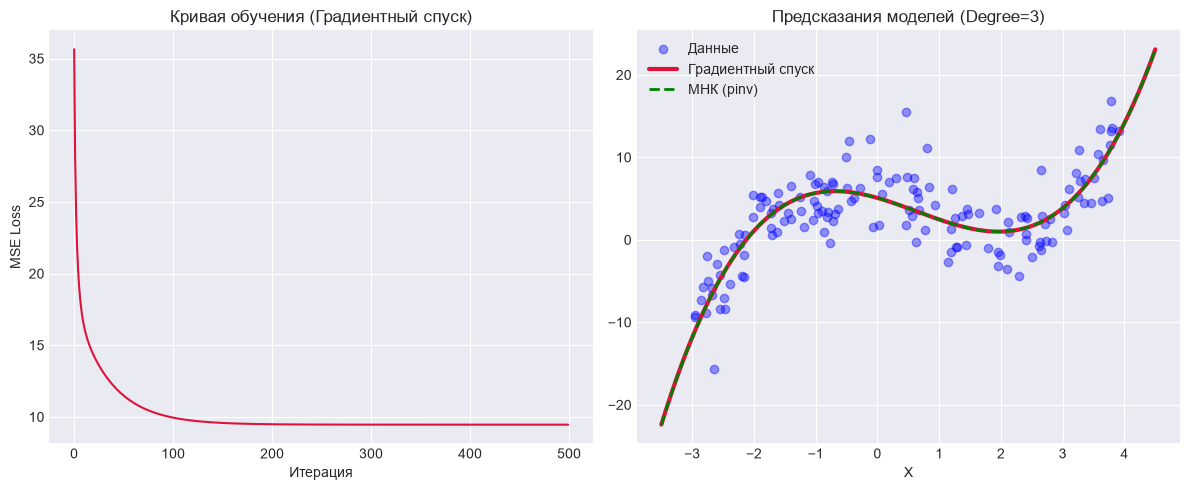

In [4]:
# Градиентный спуск
model_gd = MyPolynomialRegression(degree=3, method='gd', learning_rate=0.1, n_iters=500)
model_gd.fit(X, y)
y_pred_gd = model_gd.predict(X)

# Аналитическое решение
model_an = MyPolynomialRegression(degree=3, method='analytical')
model_an.fit(X, y)
y_pred_an = model_an.predict(X)

print("Градиентный спуск")
print(f"MSE: {model_gd.mse(y, y_pred_gd):.4f}")
print(f"R^2: {model_gd.r2_score(y, y_pred_gd):.4f}\n")

print("Аналитическое решение (МНК)")
print(f"MSE: {model_an.mse(y, y_pred_an):.4f}")
print(f"R^2: {model_an.r2_score(y, y_pred_an):.4f}")

# 1. График падения ошибки (Loss Curve)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(model_gd.loss_history, color='crimson')
plt.title('Кривая обучения (Градиентный спуск)')
plt.xlabel('Итерация')
plt.ylabel('MSE Loss')

# 2. График предсказаний
plt.subplot(1, 2, 2)
plt.scatter(X, y, color='blue', alpha=0.4, label='Данные')

y_plot_gd = model_gd.predict(X_plot)
y_plot_an = model_an.predict(X_plot)

plt.plot(X_plot, y_plot_gd, color='crimson', linewidth=3, label='Градиентный спуск')
plt.plot(X_plot, y_plot_an, color='green', linestyle='--', linewidth=2, label='МНК (pinv)')

plt.title('Предсказания моделей (Degree=3)')
plt.xlabel('X')
plt.legend()
plt.tight_layout()
plt.show()